In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Adjust the path based on your notebook's working directory
path = Path(r"C:\Users\abdul\Documents\BIA\ML\Ecommerce_Delivery_Prediction\datasets\E_Commerce.csv")



df = pd.read_csv(path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10999, 12)


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [3]:
target = "Reached.on.Time_Y.N"

# Remove the identifier and target from inputs
X = df.drop(columns=["ID", target])

y = df[target].astype(int)

print("Features:", X.columns.tolist())
print("Target distribution:")
print(y.value_counts())

Features: ['Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms']
Target distribution:
Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64


In [4]:
X = X.drop(
    columns=["Customer_rating", "Customer_care_calls"],
    errors="ignore"
)

print("Selected features:", X.columns.tolist())

Selected features: ['Warehouse_block', 'Mode_of_Shipment', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data: (8799, 8)
Testing data: (2200, 8)

Training target distribution:
Reached.on.Time_Y.N
1    0.596659
0    0.403341
Name: proportion, dtype: float64

Testing target distribution:
Reached.on.Time_Y.N
1    0.596818
0    0.403182
Name: proportion, dtype: float64


In [6]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']

Categorical features:
['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [8]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (8799, 17)
Testing shape: (2200, 17)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.base import clone
from sklearn.pipeline import Pipeline
import pandas as pd

In [10]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [11]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", clone(model))
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest,0.6627,0.7459,0.6596,0.7001,0.7369
0,Logistic Regression,0.6341,0.7009,0.6748,0.6876,0.7194
3,Gradient Boosting,0.6795,0.9075,0.5156,0.6576,0.7480
1,Decision Tree,0.6764,0.9203,0.5011,0.6489,0.7458


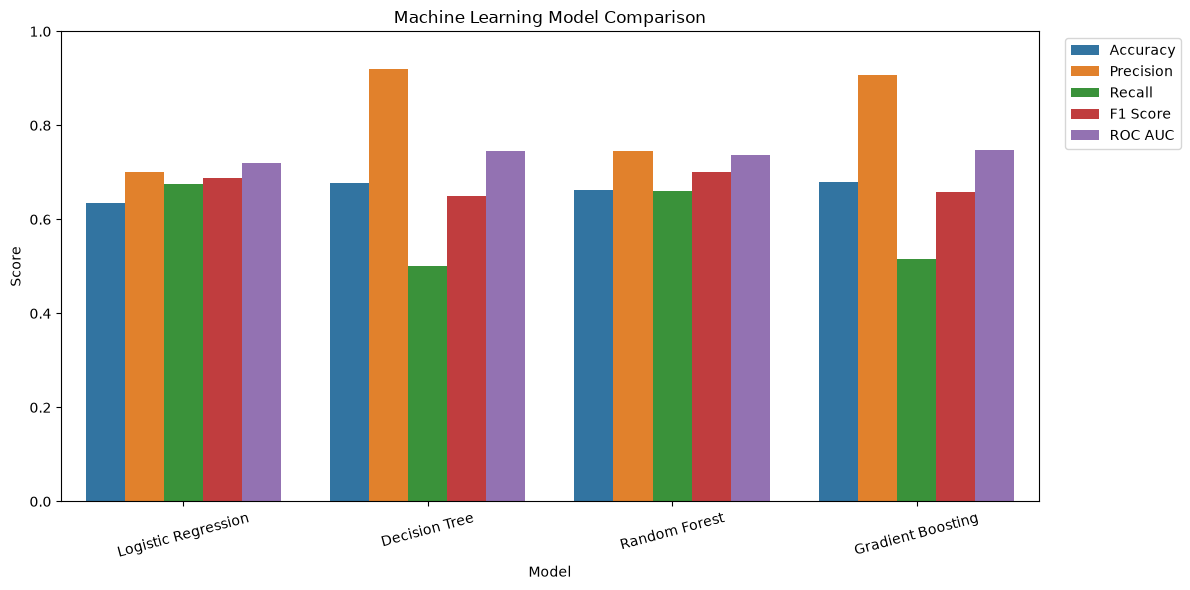

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [13]:
best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

y_pred = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["On Time", "Delayed"]
))

Best Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

     On Time       0.57      0.67      0.61       887
     Delayed       0.75      0.66      0.70      1313

    accuracy                           0.66      2200
   macro avg       0.66      0.66      0.66      2200
weighted avg       0.67      0.66      0.67      2200



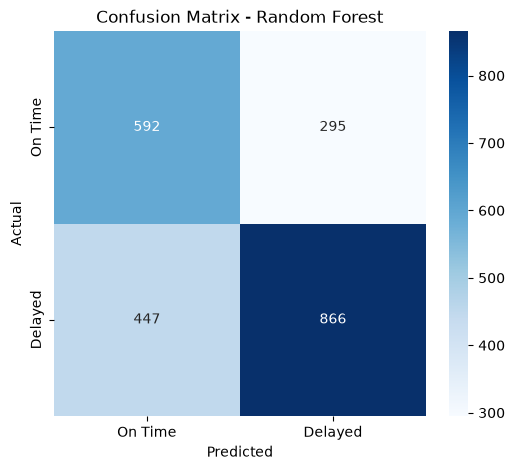

In [14]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["On Time", "Delayed"],
    yticklabels=["On Time", "Delayed"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [15]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

rf_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1:")
print(random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': None, 'classifier__class_weight': None}

Best Cross-Validation F1:
0.6877433602139684


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

tuned_model = random_search.best_estimator_

y_pred_tuned = tuned_model.predict(X_test)
y_prob_tuned = tuned_model.predict_proba(X_test)[:, 1]

print("Tuned Random Forest Results")
print("-" * 35)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))
print("ROC AUC:", roc_auc_score(y_test, y_prob_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

Tuned Random Forest Results
-----------------------------------
Accuracy: 0.65
Precision: 0.7479452054794521
Recall: 0.6237623762376238
F1 Score: 0.6802325581395349
ROC AUC: 0.7374309974575638

Classification Report:
              precision    recall  f1-score   support

           0       0.55      0.69      0.61       887
           1       0.75      0.62      0.68      1313

    accuracy                           0.65      2200
   macro avg       0.65      0.66      0.65      2200
weighted avg       0.67      0.65      0.65      2200



In [17]:
from sklearn.metrics import classification_report
from sklearn.base import clone

ordered_df = df.sort_values("ID").reset_index(drop=True)

ordered_X = ordered_df[X.columns]
ordered_y = ordered_df["Reached.on.Time_Y.N"]

split_point = int(len(ordered_df) * 0.8)

X_train_ordered = ordered_X.iloc[:split_point]
X_test_ordered = ordered_X.iloc[split_point:]

y_train_ordered = ordered_y.iloc[:split_point]
y_test_ordered = ordered_y.iloc[split_point:]

ordered_model = clone(tuned_model)

ordered_model.fit(
    X_train_ordered,
    y_train_ordered
)

ordered_predictions = ordered_model.predict(
    X_test_ordered
)

print("ID-Ordered Holdout Results:")
print(classification_report(
    y_test_ordered,
    ordered_predictions,
    zero_division=0
))

ID-Ordered Holdout Results:
              precision    recall  f1-score   support

           0       0.57      0.62      0.60      1274
           1       0.41      0.36      0.38       926

    accuracy                           0.51      2200
   macro avg       0.49      0.49      0.49      2200
weighted avg       0.50      0.51      0.51      2200



          count      mean  Delay_Percentage
ID_Group                                   
0          1100  1.000000        100.000000
1          1100  1.000000        100.000000
2          1100  0.916364         91.636364
3          1100  0.433636         43.363636
4          1100  0.438182         43.818182
5          1099  0.456779         45.677889
6          1100  0.438182         43.818182
7          1100  0.441818         44.181818
8          1100  0.410909         41.090909
9          1100  0.430909         43.090909


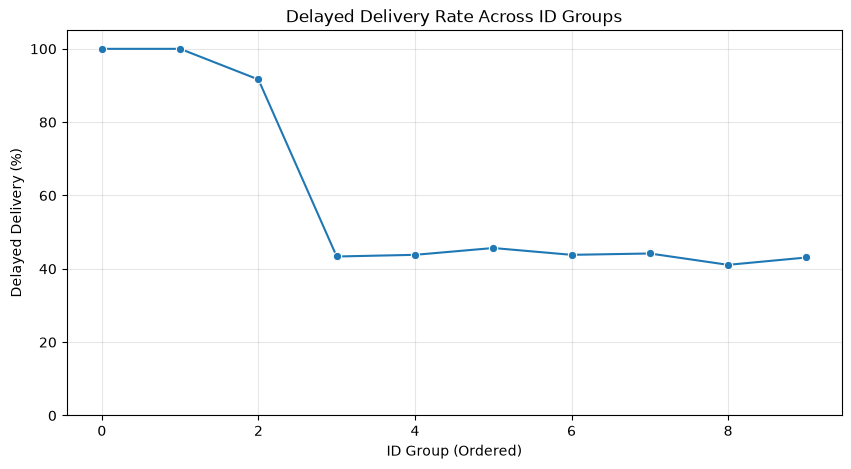

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

diagnostic_df = df.sort_values("ID").copy()

diagnostic_df["ID_Group"] = pd.qcut(
    diagnostic_df["ID"],
    q=10,
    labels=False,
    duplicates="drop"
)

delay_by_group = (
    diagnostic_df.groupby("ID_Group")
    ["Reached.on.Time_Y.N"]
    .agg(["count", "mean"])
)

delay_by_group["Delay_Percentage"] = (
    delay_by_group["mean"] * 100
)

print(delay_by_group)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=delay_by_group.reset_index(),
    x="ID_Group",
    y="Delay_Percentage",
    marker="o"
)

plt.title("Delayed Delivery Rate Across ID Groups")
plt.xlabel("ID Group (Ordered)")
plt.ylabel("Delayed Delivery (%)")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.show()

In [19]:
features_to_check = [
    "Discount_offered",
    "Weight_in_gms",
    "Cost_of_the_Product",
    "Prior_purchases"
]

group_summary = diagnostic_df.groupby(
    "ID_Group"
)[features_to_check].mean()

display(group_summary.round(2))

,Discount_offered,Weight_in_gms,Cost_of_the_Product,Prior_purchases
ID_Group,,,,
0,32.79,2347.26,193.91,3.20
1,33.22,2397.57,198.63,3.43
2,29.06,2706.13,195.64,3.28
3,5.40,4884.61,201.33,3.37
4,5.60,4471.07,214.80,3.49
5,5.43,3947.22,221.71,3.68
6,5.57,3964.20,218.66,3.80
7,5.50,4026.13,218.82,3.72
8,5.54,3846.29,220.88,3.78


In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_pred))

print("Baseline Delayed F1:",
      f1_score(y_test, baseline_pred))

print("Baseline Delayed Recall:",
      recall_score(y_test, baseline_pred))

Baseline Accuracy: 0.5968181818181818
Baseline Delayed F1: 0.7475092513521207
Baseline Delayed Recall: 1.0


In [21]:
stable_df = diagnostic_df[
    diagnostic_df["ID_Group"] >= 3
].copy()

print("Stable dataset shape:", stable_df.shape)

print("\nTarget distribution:")
print(
    stable_df["Reached.on.Time_Y.N"]
    .value_counts(normalize=True)
)

Stable dataset shape: (7699, 13)

Target distribution:
Reached.on.Time_Y.N
0    0.564229
1    0.435771
Name: proportion, dtype: float64


In [22]:
X_stable = stable_df[X.columns]
y_stable = stable_df["Reached.on.Time_Y.N"]

X_train_stable, X_test_stable, y_train_stable, y_test_stable = (
    train_test_split(
        X_stable,
        y_stable,
        test_size=0.2,
        random_state=42,
        stratify=y_stable
    )
)

In [23]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

stable_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

stable_model.fit(X_train_stable, y_train_stable)

stable_pred = stable_model.predict(X_test_stable)
stable_prob = stable_model.predict_proba(X_test_stable)[:, 1]

print("Stable Subset Classification Report:")
print(classification_report(y_test_stable, stable_pred))

print(
    "ROC AUC:",
    roc_auc_score(y_test_stable, stable_prob)
)

Stable Subset Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.89      0.69       869
           1       0.41      0.10      0.16       671

    accuracy                           0.54      1540
   macro avg       0.48      0.49      0.42      1540
weighted avg       0.49      0.54      0.46      1540

ROC AUC: 0.5032404445900268


In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent")

dummy.fit(X_train_stable, y_train_stable)

dummy_pred = dummy.predict(X_test_stable)

print("Baseline Accuracy:",
      accuracy_score(y_test_stable, dummy_pred))

print("Random Forest Accuracy:",
      accuracy_score(y_test_stable, stable_pred))

print("Baseline Delayed F1:",
      f1_score(y_test_stable, dummy_pred, zero_division=0))

print("Random Forest Delayed F1:",
      f1_score(y_test_stable, stable_pred))

Baseline Accuracy: 0.5642857142857143
Random Forest Accuracy: 0.5448051948051948
Baseline Delayed F1: 0.0
Random Forest Delayed F1: 0.15846338535414164


In [25]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import pandas as pd

models_cv = {
    "Baseline": DummyClassifier(
        strategy="most_frequent"
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models_cv.items():

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", clone(model))
    ])

    scores = cross_validate(
        pipeline,
        X_train_stable,
        y_train_stable,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.sort_values(
        "F1 Score",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest,0.5454,0.4278,0.1293,0.1983,0.5028
3,Gradient Boosting,0.5480,0.4267,0.1069,0.1704,0.5053
1,Logistic Regression,0.5618,0.5056,0.0257,0.0478,0.5044
0,Baseline,0.5642,0.0000,0.0000,0.0000,0.5000


In [26]:
import joblib
from pathlib import Path

# Original Random Forest pipeline
demo_model = trained_models["Random Forest"]

model_path = Path("../models/delivery_model.pkl")

# Fallback when notebook runs from project root
if not model_path.parent.exists():
    model_path = Path("models/delivery_model.pkl")

model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(demo_model, model_path)

print("Model saved successfully!")
print("Location:", model_path.resolve())

Model saved successfully!
Location: C:\Users\abdul\Documents\BIA\ML\Ecommerce_Delivery_Prediction\models\delivery_model.pkl


In [27]:
loaded_model = joblib.load(model_path)

sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)[0]
probability = loaded_model.predict_proba(sample)[0]

print("Prediction:", "Delayed" if prediction == 1 else "On Time")
print("Class probabilities:", probability)

Prediction: Delayed
Class probabilities: [0. 1.]


In [28]:
import joblib
from pathlib import Path

# Use the original trained Random Forest pipeline
model = trained_models["Random Forest"]

# Find the project folder
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

# Create models folder if it doesn't exist
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save model
model_path = models_dir / "delivery_model.pkl"

joblib.dump(model, model_path)

print("Model saved successfully!")
print("Location:", model_path.resolve())

Model saved successfully!
Location: C:\Users\abdul\Documents\BIA\ML\Ecommerce_Delivery_Prediction\models\delivery_model.pkl
